# FairAge presentation figures

Run the cells in order to generate Figures 00–08 from the published CSVs.


# Imports

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap

from fairage.data import AGE_CLASSES, RACE_GROUPS, SPLITS
from fairage.plots import DISPLAY_LABELS

ROOT = Path.cwd().resolve()
while not (ROOT / "results/published/dataset_counts.csv").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the FairAge repository.")
    ROOT = ROOT.parent


# Repository and experiment setup

In [16]:
PUBLISHED = ROOT / "results/published"
models = (pd.read_csv(PUBLISHED / "models.csv")
          .rename(columns={"selected_epoch": "epoch"}).set_index("run"))
RUNS = models.index.tolist()
BASELINES = RUNS[:2]
TUNED = RUNS[3:]
AGE_LABELS = [DISPLAY_LABELS.get(age, age) for age in AGE_CLASSES]
RACE_LABELS = [DISPLAY_LABELS.get(race, race) for race in RACE_GROUPS]
print(f"Published models: {len(RUNS)}")
print(f"Recorded frozen partition sizes: {SPLITS}")


Published models: 5
Recorded frozen partition sizes: {'train': 77805, 'development': 8645, 'holdout': 10954}


# Shared visualization styling

In [17]:

# Okabe–Ito categorical palette
PALETTE = {
    "blue": "#0072B2",
    "vermilion": "#D55E00",
    "green": "#009E73",
    "orange": "#E69F00",
    "sky_blue": "#56B4E9",
    "purple": "#CC79A7",
    "yellow": "#F0E442",
    "black": "#000000",
    "gray": "#595959",
}

MODEL_COLORS = dict(zip(
    RUNS,
    [PALETTE["blue"], PALETTE["vermilion"], PALETTE["gray"],
     PALETTE["blue"], PALETTE["vermilion"]]
))

# Confidence bars encode metrics, separately from model identity colors.
CONFIDENCE_COLORS = {
    "accuracy": PALETTE["gray"],
    "mean_confidence": PALETTE["vermilion"],
}

# Neutral interface colors. Distinct approved grays are intentionally retained.
NEUTRAL_COLORS = {
    "white": "white",
    "text": "#111111",
    "secondary_text": "#555555",
    "annotation_text": "#444444",
    "footer_text": "#666666",
    "dark": "#333333",
    "grid": "#E5E5E5",
    "column_separator": "#707780",
    "group_separator": "#9299A1",
    "low_support_hatch": "#999999",
    "masked_cell": "#ECEFF1",
}

# Dataset heatmap and highlighted totals row (keep light fills for black numbers).
DATASET_COLORS = {
    "highlight": "#61ADD2",
    "other_totals": "#E6EEF5",
    "border": "#8194A8",
}
DATASET_CMAP = LinearSegmentedColormap.from_list(
    "fairage_blue",
    ["#F4F8FB", "#D9E8F2", "#B4D5E8", "#8CC2DE", DATASET_COLORS["highlight"]],
)

# Categorical prediction-distance colors and their existing hatch/edge colors.
ERROR_COLORS = {
    "correct": PALETTE["blue"],
    "one_away": "#F0CC80",
    "two_or_more_away": "#888888",
    "one_away_hatch": "#8B7650",
    "two_or_more_hatch": "#F4F4F4",
}
CONFUSION_CMAP = LinearSegmentedColormap.from_list(
    "fairage_errors",
    ["#F2F6FA", "#CFE3F0", "#ACD1E6", "#83BBD8", "#5C9FC6"],
)

# Continuous accuracy differences: existing blue / zero / warm gradient.
DIFFERENCE_CMAP = LinearSegmentedColormap.from_list(
    "fairage_difference",
    ["#5C9FC6", "#F7F7F7", "#D98E66"],
)
DIFFERENCE_CMAP.set_bad(NEUTRAL_COLORS["masked_cell"])

# Figure cells reference these groups; approved literal colors live only here.

# Shared roles without dedicated rcParams; intentional per-figure overrides stay local.
STYLE = {
    "annotation_size": 14,
    "group_label_size": 13,
    "note_size": 10.5,
    "emphasis_weight": "semibold",
    "strong_weight": "bold",
    "hidden_tick_length": 0,
    "cell_border_width": 1.2,
    "hatch_border_width": 0.4,
    "column_separator_width": 2.8,
    "group_separator_width": 2.0,
}

# Main titles use figure.* (including the two single-axis chart titles).
# Panel titles use axes.*; special column headings retain their local 18-point size.
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 16,
    "font.weight": "normal",
    "text.color": PALETTE["black"],
    "figure.titlesize": 22,
    "figure.titleweight": "bold",
    "axes.titlesize": 17,
    "axes.titleweight": "semibold",
    "axes.titlepad": 28,
    "axes.labelsize": 16,
    "axes.labelweight": "semibold",
    "axes.labelpad": 12,
    "axes.labelcolor": PALETTE["black"],
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "legend.fontsize": 16,
    "legend.frameon": False,
    "figure.figsize": (16, 9),
    "figure.facecolor": NEUTRAL_COLORS["white"],
    "savefig.facecolor": NEUTRAL_COLORS["white"],
    "axes.facecolor": NEUTRAL_COLORS["white"],
    "axes.edgecolor": PALETTE["black"],
    "axes.linewidth": 0.8,
    "grid.color": NEUTRAL_COLORS["grid"],
    "grid.linewidth": 1,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# Load Public Data


In [18]:
published = {name: pd.read_csv(PUBLISHED / f"{name}.csv") for name in (
    "histories", "evaluations", "confusion", "age_race", "dataset_counts",
)}
dataset_counts = published["dataset_counts"]
histories = {run: published["histories"].query("run == @run").copy() for run in RUNS}
development = {"metrics": published["evaluations"].query("split == 'development'").copy()}
holdout = {"metrics": published["evaluations"].query("split == 'holdout'").copy()}
evidence = {
    split: {
        run: {"confusion": published["confusion"].query("run == @run and split == @split")
              .pivot(index="true_age", columns="predicted_age", values="count")
              .reindex(index=AGE_CLASSES, columns=AGE_CLASSES)}
        for run in RUNS
    }
    for split in ("development", "holdout")
}
print("Loaded six necessary aggregate CSVs, including models; no individual research records are read.")


Loaded six necessary aggregate CSVs, including models; no individual research records are read.


## Check the inputs

Check the selected checkpoints, evaluation precision, and image counts before plotting.


In [19]:
# Validate published evidence before plotting.
fixed_epochs = {
    "lean-scratch-s4531": 28, "lean-pretrained-s4531": 44, "lean-frozen-s4531": 36,
    "optuna-scratch-trial-0011": 55, "optuna-pretrained-trial-0128": 9,
}
if RUNS != list(fixed_epochs) or models.epoch.to_dict() != fixed_epochs:
    raise ValueError("Preserve the five fixed model identities/checkpoint epochs")

for split in ("development", "holdout"):
    metrics = published["evaluations"].query("split == @split").set_index("run")
    if (metrics.index.tolist() != RUNS or not metrics.epoch.equals(models.epoch)
            or not metrics.checkpoint.eq("best").all()
            or not metrics.evaluation_precision.eq("fp32").all()
            or not metrics.support.eq(SPLITS[split]).all()):
        raise ValueError(f"{split}: fixed FP32 evaluation context changed")
    for run in RUNS:
        counts = evidence[split][run]["confusion"].to_numpy()
        if not np.isfinite(counts).all() or counts.sum() != SPLITS[split]:
            raise ValueError(f"{run}/{split}: incomplete confusion counts")

counts = dataset_counts.query("population == 'frozen_training'")
if len(counts) != 63 or counts.support.sum() != SPLITS["train"]:
    raise ValueError("frozen_training: incomplete aggregate distribution")
cells = published["age_race"]
if (cells.support.isna().any() or (cells.support < 0).any()
        or not cells.suppressed.equals(cells.support < 30)
        or not cells.loc[cells.suppressed, "accuracy"].isna().all()
        or not cells.loc[~cells.suppressed, "accuracy"].between(0, 1).all()):
    raise ValueError("Release all counts; suppressed accuracies must remain missing")
print("Verified fixed checkpoints and FP32 evaluation context/counts.")


Verified fixed checkpoints and FP32 evaluation context/counts.


## Fig. 00. Training images by age

Counts use the 77,805 images in the study’s training split after exclusions.


,support
age,
0-2,1608
3-9,9286
10-19,8150
20-29,22990
30-39,17289
40-49,9642
50-59,5591
60-69,2495
more than 70,754


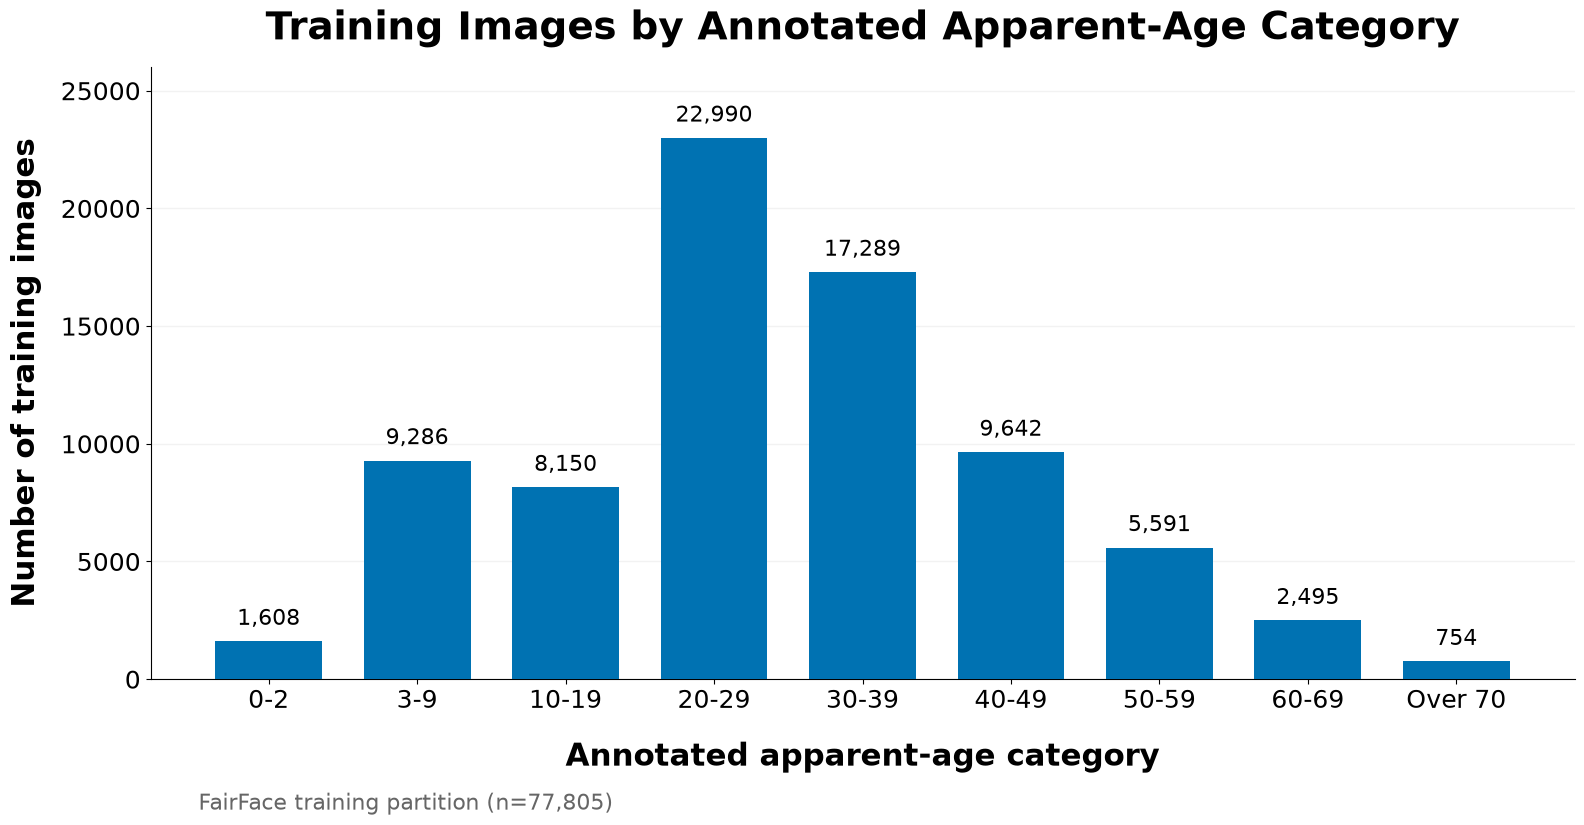

In [20]:
frozen_age_counts = (dataset_counts.query("population == 'frozen_training'")
                     .groupby("age").support.sum().reindex(AGE_CLASSES).to_frame("support"))
if frozen_age_counts.support.isna().any() or frozen_age_counts.support.sum() != 77_805:
    raise ValueError("Figure 00 requires all nine frozen-training ages totaling 77,805.")
display(frozen_age_counts)

fig, ax = plt.subplots()
fig.subplots_adjust(left=0.10, right=0.99, top=0.88, bottom=0.20)
bars = ax.bar(
    np.arange(len(AGE_CLASSES)), frozen_age_counts.support.to_numpy(),
    width=0.72, color=PALETTE["blue"], zorder=3,
)
ax.bar_label(bars, labels=[f"{n:,}" for n in frozen_age_counts.support],
             padding=8, fontsize=16)
ax.set_title("Training Images by Annotated Apparent-Age Category",
             fontsize=28, fontweight="bold", pad=20)
ax.set_xticks(range(len(AGE_CLASSES)), AGE_LABELS)
ax.set_xlabel("Annotated apparent-age category", fontsize=22, fontweight="bold", labelpad=20)
ax.set_ylabel("Number of training images", fontsize=22, fontweight="bold", labelpad=14)
ax.set_ylim(0, 26_000)
ax.set_yticks(np.arange(0, 25_001, 5_000))
ax.tick_params(axis="both", labelsize=18)
ax.grid(visible=True, axis="y", color="#F2F2F2")
ax.set_axisbelow(True)
fig.text(0.13, 0.055, f"FairFace training partition (n={frozen_age_counts.support.sum():,})",
         fontsize=16, color=NEUTRAL_COLORS["footer_text"])
plt.show()


## Fig. 01. Training images by age and race

Each cell gives the image count for one apparent-age category and annotated racial group.


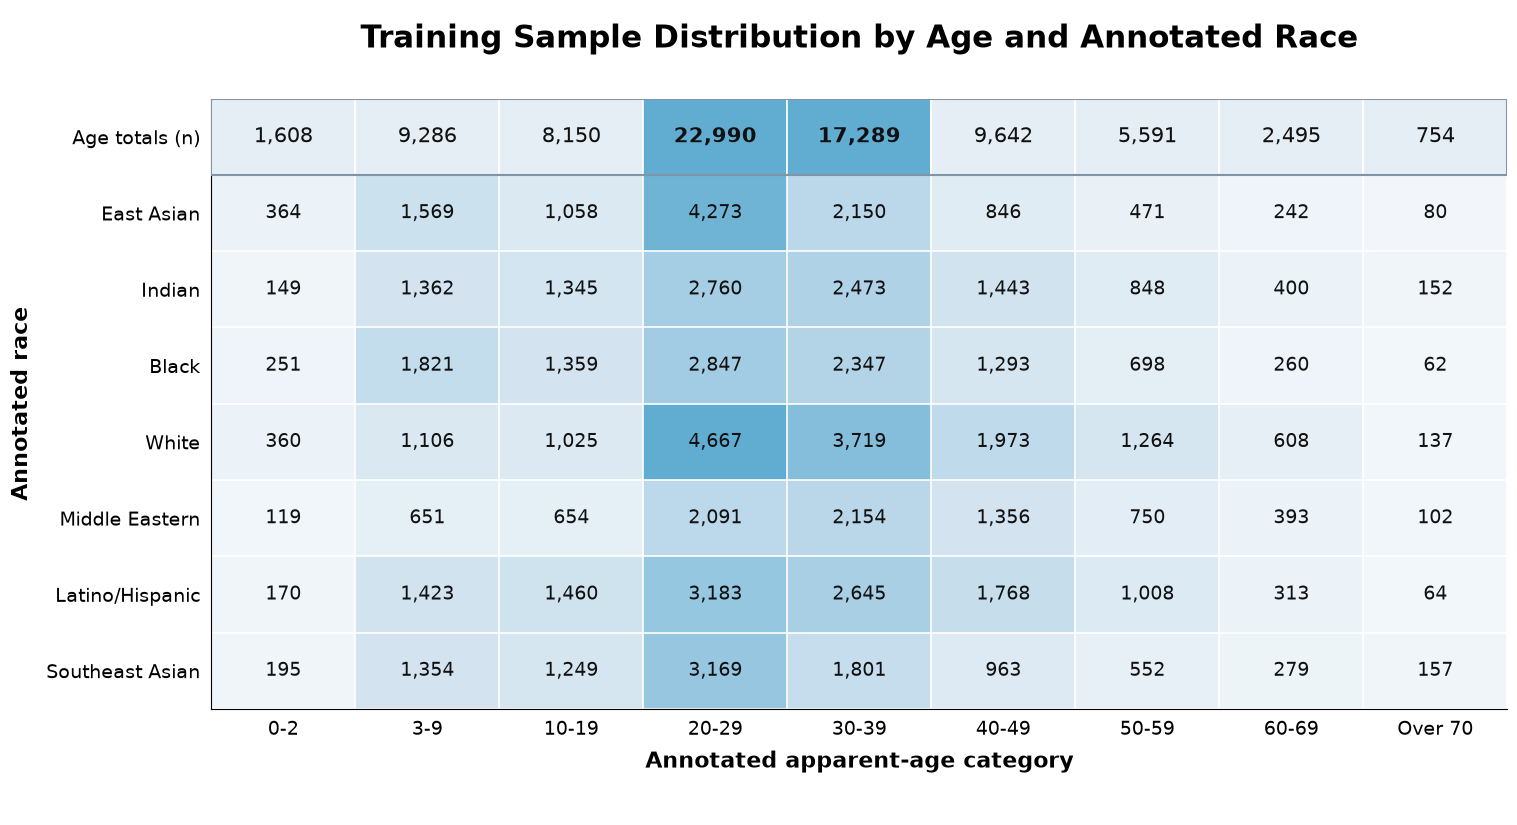

In [21]:
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

# Frozen training counts, not the publisher-training population used in Notebook 01.
counts = (dataset_counts.query("population == 'frozen_training'")
          .pivot(index="race", columns="age", values="support")
          .reindex(index=RACE_GROUPS, columns=AGE_CLASSES))
values = counts.to_numpy()
age_totals = counts.sum(axis=0)
if counts.isna().any().any() or values.sum() != SPLITS["train"]:
    raise ValueError("Training counts do not match the frozen partition.")

# Shared Colors
HIGHLIGHT_BLUE = DATASET_COLORS["highlight"]
blue_map = DATASET_CMAP

norm = Normalize(vmin=0, vmax=values.max())
fig = plt.figure()

grid = fig.add_gridspec(
    3, 1,
    height_ratios=[0.7, 7.2, 0.9],
    left=0.155,
    right=0.965,
    top=0.965,
    bottom=0.07,
    hspace=0.12,
)

ax_title = fig.add_subplot(grid[0])
ax = fig.add_subplot(grid[1])
ax_footer = fig.add_subplot(grid[2])

ax_title.axis("off")
ax_footer.axis("off")

# Title
ax_title.text(
    0.5, 0.5,
    "Training Sample Distribution by Age and Annotated Race",
    transform=ax_title.transAxes,
    ha="center",
    va="center",
    fontsize=mpl.rcParams["figure.titlesize"],
    fontweight=mpl.rcParams["figure.titleweight"],
)

# Heatmap and Age Totals

image = ax.imshow(
    values,
    cmap=blue_map,
    norm=norm,
    origin="upper",
    interpolation="nearest",
    aspect="auto",
    extent=(-0.5, 8.5, 6.5, -0.5),
)

# Totals row above the heatmap
for col, age in enumerate(AGE_CLASSES):
    highlighted = age in ("20-29", "30-39")

    ax.add_patch(
        Rectangle(
            (col - 0.5, -1.5),
            1, 1,
            facecolor=HIGHLIGHT_BLUE if highlighted else DATASET_COLORS["other_totals"],
            edgecolor=NEUTRAL_COLORS["white"],
            linewidth=STYLE["cell_border_width"],
            zorder=3,
        )
    )

    ax.text(
        col, -1,
        f"{age_totals[age]:,}",
        ha="center",
        va="center",
        fontsize=15,
        fontweight=STYLE["strong_weight"] if highlighted else mpl.rcParams["font.weight"],
        color=NEUTRAL_COLORS["text"],
        zorder=5,
    )

# Counts inside heatmap cells
for row in range(len(RACE_GROUPS)):
    for col in range(len(AGE_CLASSES)):
        ax.text(
            col, row,
            f"{int(values[row, col]):,}",
            ha="center",
            va="center",
            fontsize=STYLE["annotation_size"],
            color=NEUTRAL_COLORS["text"],
            zorder=4,
        )

# Axes and Labels
ax.set_xlim(-0.5, 8.5)
ax.set_ylim(6.5, -1.5)

ax.set_xticks(range(len(AGE_CLASSES)))
ax.set_xticklabels(AGE_LABELS)

ax.set_yticks([-1, *range(len(RACE_GROUPS))])
ax.set_yticklabels(["Age totals (n)", *RACE_LABELS])

ax.set_xlabel(
    "Annotated apparent-age category",
    labelpad=8,
)

ax.set_ylabel(
    "Annotated race",
    labelpad=10,
)

ax.tick_params(
    axis="both",
    length=STYLE["hidden_tick_length"],
    pad=8,
)

# Cell Boundaries
ax.set_xticks(np.arange(-0.5, len(AGE_CLASSES), 1), minor=True)
ax.set_yticks(np.arange(-1.5, len(RACE_GROUPS), 1), minor=True)

ax.grid(
    which="minor",
    color=NEUTRAL_COLORS["white"],
    linewidth=STYLE["cell_border_width"],
)
ax.tick_params(which="minor", bottom=False, left=False)

# Outline totals row and separate it from the heatmap
ax.add_patch(
    Rectangle(
        (-0.5, -1.5),
        len(AGE_CLASSES), 1,
        fill=False,
        edgecolor=DATASET_COLORS["border"],
        linewidth=1.5,
        zorder=6,
    )
)
ax.axhline(
    -0.5,
    color=DATASET_COLORS["border"],
    linewidth=1.4,
    zorder=6,
)

plt.show()


## Fig. 02. Baseline learning curves

Development macro-F1 by epoch for the scratch and trainable pretrained baselines.


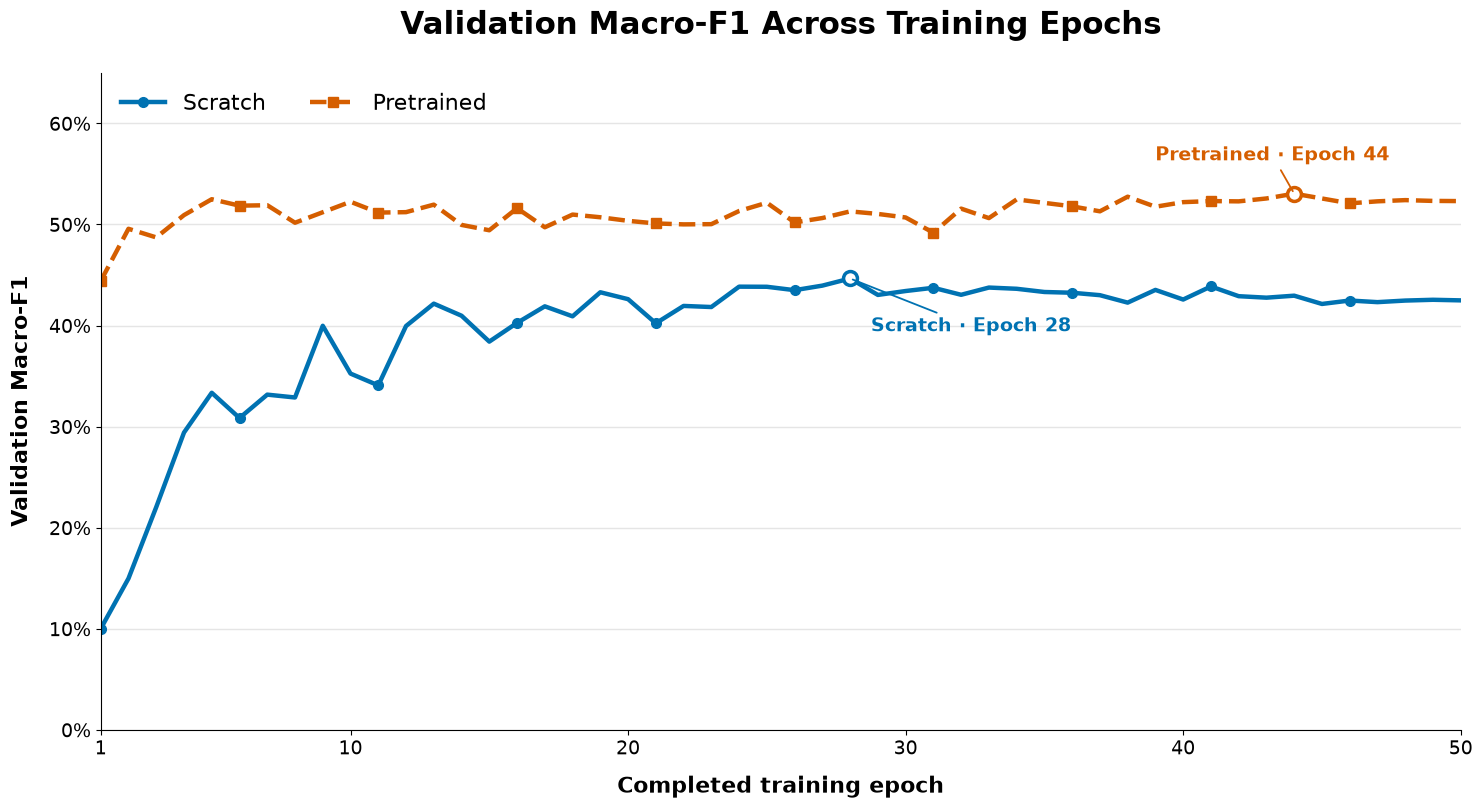

In [22]:
# Figure Layout
fig, ax = plt.subplots()

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.87,
    bottom=0.14,
)

# Model Styles
styles = {
    BASELINES[0]: {
        "label": "Scratch",
        "color": MODEL_COLORS[BASELINES[0]],
        "linestyle": "-",
        "marker": "o",
    },
    BASELINES[1]: {
        "label": "Pretrained",
        "color": MODEL_COLORS[BASELINES[1]],
        "linestyle": "--",
        "marker": "s",
    },
}

# Recorded training-time validation (development) performance
for run in BASELINES:
    history = histories[run]
    style = styles[run]

    ax.plot(
        history["epoch"],
        history["dev_macro_f1"],
        label=style["label"],
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        markevery=5,
        linewidth=3.2,
        markersize=7,
    )

# Annotate each model's best validation (development) epoch
annotations = [
    (BASELINES[0], "Scratch", (15, -38)),
    (BASELINES[1], "Pretrained", (-100, 24)),
]

for run, label, offset in annotations:
    epoch = int(models.loc[run, "epoch"])
    score = float(
        histories[run].loc[
            histories[run]["epoch"] == epoch,
            "dev_macro_f1"
        ].iloc[0]
    )

    color = styles[run]["color"]

    # Highlight the recorded checkpoint
    ax.scatter(
        epoch, score,
        s=100,
        facecolor=NEUTRAL_COLORS["white"],
        edgecolor=color,
        linewidth=2.5,
        zorder=5,
    )

    # Separate annotation for each model
    ax.annotate(
        f"{label} · Epoch {epoch}",
        xy=(epoch, score),
        xytext=offset,
        textcoords="offset points",
        fontsize=STYLE["annotation_size"],
        fontweight=STYLE["emphasis_weight"],
        color=color,
        arrowprops={
            "arrowstyle": "-",
            "color": color,
            "linewidth": 1.3,
        },
        zorder=6,
    )

# Title
ax.set_title(
    "Validation Macro-F1 Across Training Epochs",
    fontsize=mpl.rcParams["figure.titlesize"],
    fontweight=mpl.rcParams["figure.titleweight"],
)

# Axes and Labels
ax.set_xlabel("Completed training epoch")

ax.set_ylabel("Validation Macro-F1")

ax.set_xlim(1, 50)
ax.set_xticks([1, 10, 20, 30, 40, 50])

ax.set_ylim(0, 0.65)
ax.set_yticks(np.arange(0, 0.61, 0.10))
ax.yaxis.set_major_formatter(PercentFormatter(1))

# Subtle horizontal grid
ax.grid(visible=True, axis="y")
ax.set_axisbelow(True)

# Top/right spines follow the shared styling cell defaults.

# Simple model legend
ax.legend(
    loc="upper left",
    ncol=2,
)

# Preview only
plt.show()


## Figs. 03–04. Holdout scores

Figure 03 compares the five selected models. Figure 04 subtracts each model’s FP32 development macro-F1 from its FP32 holdout macro-F1.


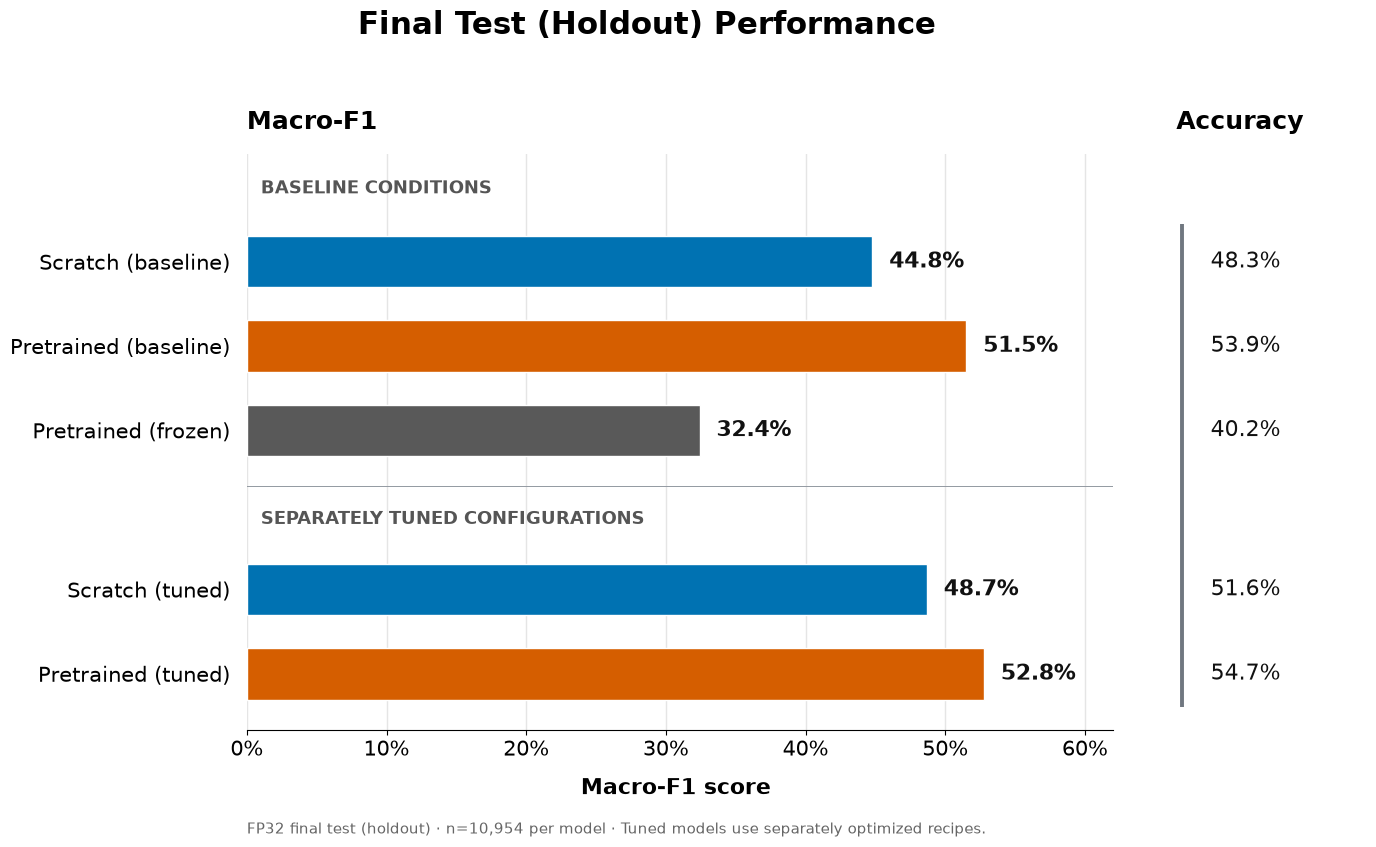

In [23]:
# Saved FP32 holdout results
scores = holdout["metrics"].set_index("run").loc[RUNS]

positions = np.array([5.0, 4.1, 3.2, 1.5, 0.6])
labels = models.loc[RUNS, "label"].tolist()
colors = [MODEL_COLORS[run] for run in RUNS]

# Figure Layout
fig = plt.figure()

grid = fig.add_gridspec(
    1, 2,
    width_ratios=[5, 1.1],
    left=0.25,
    right=0.95,
    top=0.81,
    bottom=0.17,
    wspace=0.12,
)

ax = fig.add_subplot(grid[0])
ax_accuracy = fig.add_subplot(grid[1], sharey=ax)

# Title
fig.suptitle(
    "Final Test (Holdout) Performance",
    y=0.97,
)

# Metric headings (intentional 18-point column headers)
ax.set_title(
    "Macro-F1",
    fontsize=18,
    loc="left",
    pad=18,
)

ax_accuracy.set_title(
    "Accuracy",
    fontsize=18,
    loc="left",
    pad=18,
)

# Macro-F1 bars

bars = ax.barh(
    positions,
    scores["macro_f1"].to_numpy(),
    height=0.55,
    color=colors,
    edgecolor=NEUTRAL_COLORS["white"],
    linewidth=1,
    zorder=3,
)

# Direct F1 labels
for bar, score in zip(bars, scores["macro_f1"]):
    ax.text(
        bar.get_width() + 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.1%}",
        ha="left",
        va="center",
        fontweight=STYLE["emphasis_weight"],
        color=NEUTRAL_COLORS["text"],
    )

# Accuracy column

ax_accuracy.set_xlim(0, 1)
ax_accuracy.set_ylim(0, 6.15)

ax_accuracy.set_xticks([])
ax_accuracy.tick_params(
    axis="y",
    left=False,
    labelleft=False,
)

for spine in ax_accuracy.spines.values():
    spine.set_visible(False)

# Vertical separator — darker and thicker
ax_accuracy.vlines(
    x=0.03,
    ymin=0.25,
    ymax=5.40,
    color=NEUTRAL_COLORS["column_separator"],
    linewidth=STYLE["column_separator_width"],
    zorder=5,
)

# Accuracy values
for position, accuracy in zip(
    positions, scores["accuracy"]
):
    ax_accuracy.text(
        0.18,
        position,
        f"{accuracy:.1%}",
        ha="left",
        va="center",
        color=NEUTRAL_COLORS["text"],
    )

# Experimental groups

ax.text(
    0.01, 5.73,
    "BASELINE CONDITIONS",
    fontsize=STYLE["group_label_size"],
    fontweight=STYLE["emphasis_weight"],
    color=NEUTRAL_COLORS["secondary_text"],
)

ax.text(
    0.01, 2.20,
    "SEPARATELY TUNED CONFIGURATIONS",
    fontsize=STYLE["group_label_size"],
    fontweight=STYLE["emphasis_weight"],
    color=NEUTRAL_COLORS["secondary_text"],
)

# Horizontal separator — darker and thicker
ax.axhline(
    y=2.60,
    color=NEUTRAL_COLORS["group_separator"],
    linewidth=.7,
    zorder=2,
)

# Axes and Labels

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlim(0, 0.62)
ax.set_ylim(0, 6.15)

ax.set_xticks(np.arange(0, 0.61, 0.10))
ax.xaxis.set_major_formatter(PercentFormatter(1))

ax.set_xlabel("Macro-F1 score ")

ax.tick_params(
    axis="both",
    labelsize=15,
)

ax.tick_params(
    axis="y",
    length=STYLE["hidden_tick_length"],
    pad=12,
)

# Subtle vertical grid
ax.grid(visible=True, axis="x")
ax.set_axisbelow(True)

ax.spines["left"].set_visible(False)

# Scientific provenance
fig.text(
    0.25, 0.055,
    "FP32 final test (holdout) · n=10,954 per model · "
    "Tuned models use separately optimized recipes.",
    fontsize=STYLE["note_size"],
    color=NEUTRAL_COLORS["footer_text"],
)

# Preview only
plt.show()


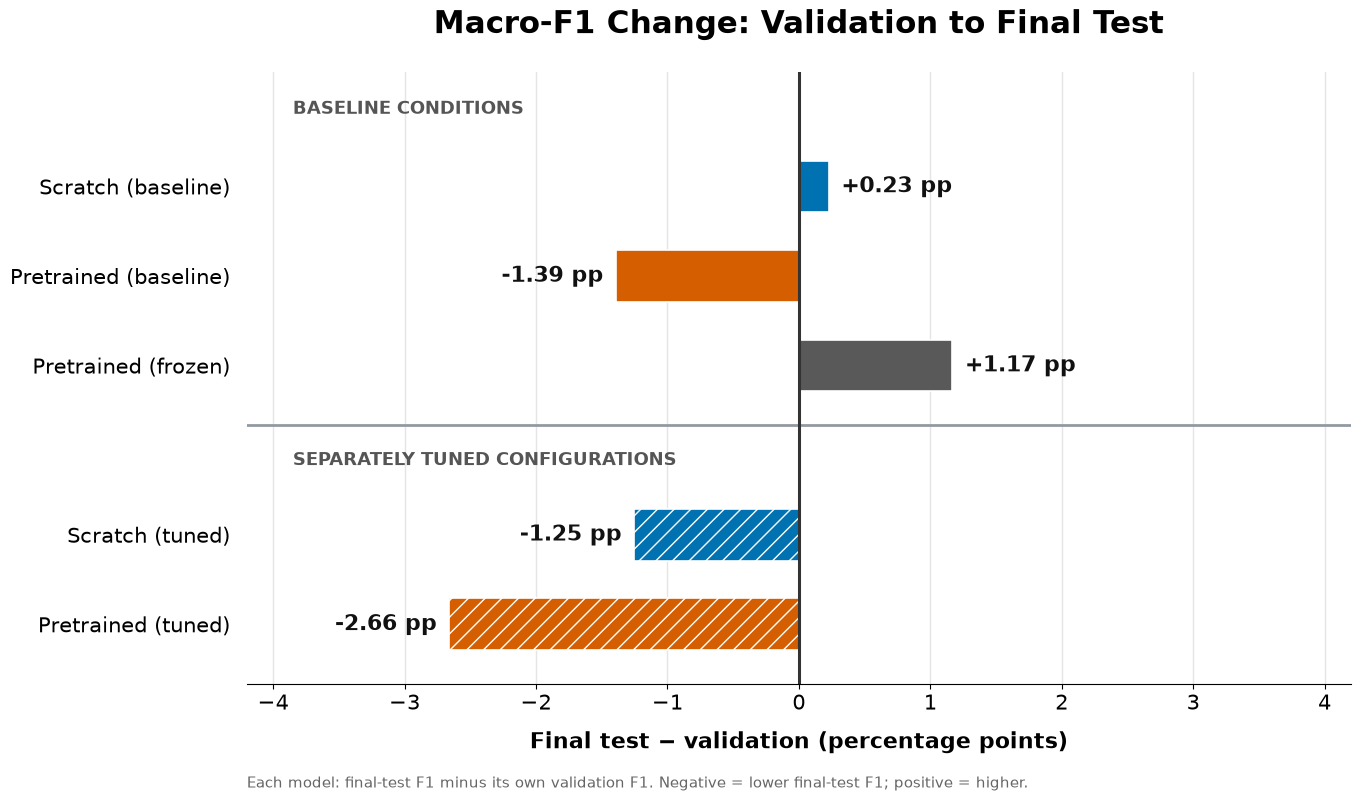

In [24]:
from matplotlib.ticker import MultipleLocator

# Saved FP32 evaluation results
dev_scores = development["metrics"].set_index("run").loc[RUNS]
hold_scores = holdout["metrics"].set_index("run").loc[RUNS]

# Final test (holdout) minus validation (development), expressed in percentage points
change_pp = (
    hold_scores["macro_f1"] - dev_scores["macro_f1"]
) * 100

positions = np.array([5.0, 4.1, 3.2, 1.5, 0.6])
labels = models.loc[RUNS, "label"].tolist()
colors = [MODEL_COLORS[run] for run in RUNS]

# Figure Layout
fig, ax = plt.subplots()

fig.subplots_adjust(
    left=0.25,
    right=0.94,
    top=0.85,
    bottom=0.17,
)

# Title
ax.set_title(
    "Macro-F1 Change: Validation to Final Test",
    fontsize=mpl.rcParams["figure.titlesize"],
    fontweight=mpl.rcParams["figure.titleweight"],
)

# Performance change bars

for run, y, color in zip(RUNS, positions, colors):
    value = float(change_pp.loc[run])
    tuned = run in TUNED

    ax.barh(
        y,
        value,
        height=0.52,
        color=color,
        hatch="//" if tuned else None,
        edgecolor=NEUTRAL_COLORS["white"],
        linewidth=1.2,
        zorder=3,
    )

    ax.annotate(
        f"{value:+.2f} pp",
        xy=(value, y),
        xytext=(9 if value >= 0 else -9, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontweight=STYLE["emphasis_weight"],
        color=NEUTRAL_COLORS["text"],
        zorder=5,
    )

# Reference and grouping

# Zero means identical validation (development) and final-test (holdout) scores.
ax.axvline(
    0,
    color=NEUTRAL_COLORS["dark"],
    linewidth=2.2,
    zorder=4,
)

# Experimental groups
ax.text(
    -3.85, 5.73,
    "BASELINE CONDITIONS",
    fontsize=STYLE["group_label_size"],
    fontweight=STYLE["emphasis_weight"],
    color=NEUTRAL_COLORS["secondary_text"],
)

ax.text(
    -3.85, 2.20,
    "SEPARATELY TUNED CONFIGURATIONS",
    fontsize=STYLE["group_label_size"],
    fontweight=STYLE["emphasis_weight"],
    color=NEUTRAL_COLORS["secondary_text"],
)

# Horizontal group separator
ax.axhline(
    2.60,
    color=NEUTRAL_COLORS["group_separator"],
    linewidth=STYLE["group_separator_width"],
)

# Axes and Labels

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xlim(-4.2, 4.2)
ax.set_ylim(0, 6.15)

ax.xaxis.set_major_locator(MultipleLocator(1))

ax.set_xlabel("Final test − validation (percentage points)")

ax.tick_params(axis="both", labelsize=15)
ax.tick_params(axis="y", length=STYLE["hidden_tick_length"], pad=12)

# Subtle vertical grid
ax.grid(visible=True, axis="x")
ax.set_axisbelow(True)

ax.spines["left"].set_visible(False)

# Comparison direction
fig.text(
    0.25, 0.055,
    "Each model: final-test F1 minus its own validation F1. "
    "Negative = lower final-test F1; positive = higher.",
    fontsize=STYLE["note_size"],
    color=NEUTRAL_COLORS["footer_text"],
)

# Preview only
plt.show()


## Fig. 05. Prediction confidence

Saved FP32 development evaluations compare mean confidence, exact-category accuracy, and errors made with more than 90% confidence before and after tuning the pretrained model.


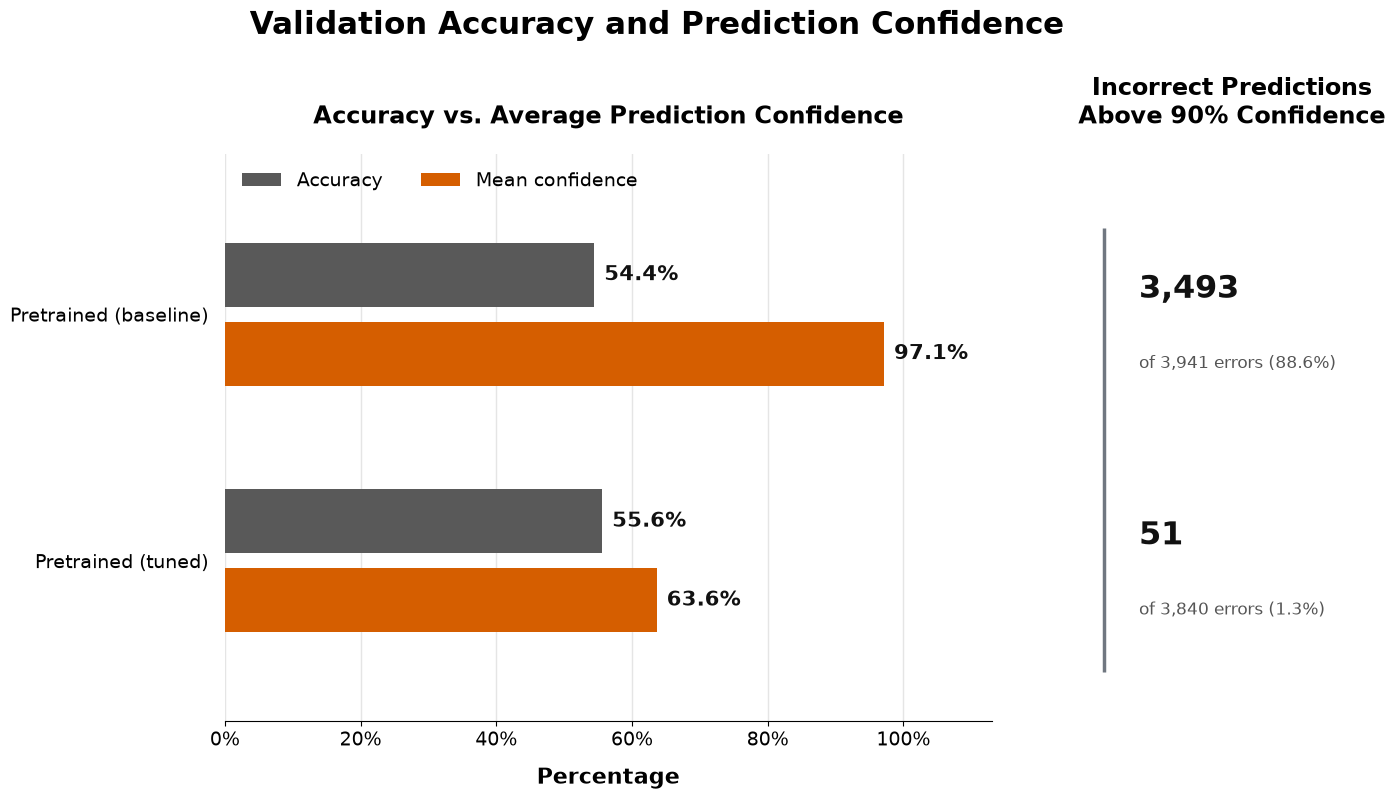

In [25]:
# Saved FP32 development population summaries, without individual predictions.
pretrained_runs = [RUNS[1], RUNS[4]]
diagnostics = (development["metrics"].set_index("run")
               .loc[pretrained_runs].to_dict("index"))

accuracy = np.array([
    diagnostics[run]["accuracy"] for run in pretrained_runs
])

confidence = np.array([
    diagnostics[run]["mean_max_probability"]
    for run in pretrained_runs
])

# Local 14-point legend and 23-point error counts are intentional.
# Figure Layout
fig = plt.figure()

grid = fig.add_gridspec(
    1, 2,
    width_ratios=[3.7, 1.4],
    left=0.23,
    right=0.95,
    top=0.80,
    bottom=0.17,
    wspace=0.18,
)

ax = fig.add_subplot(grid[0])
ax_errors = fig.add_subplot(grid[1], sharey=ax)

fig.suptitle(
    "Validation Accuracy and Prediction Confidence",
    y=0.96,
)

positions = np.array([1.2, 0.2])
labels = models.loc[pretrained_runs, "label"].tolist()

# Accuracy versus average confidence

ax.set_title(
    "Accuracy vs. Average Prediction Confidence",
    pad=22,
)

bars_accuracy = ax.barh(
    positions + 0.16,
    accuracy,
    height=0.26,
    color=CONFIDENCE_COLORS["accuracy"],
    label="Accuracy",
    zorder=3,
)

bars_confidence = ax.barh(
    positions - 0.16,
    confidence,
    height=0.26,
    color=CONFIDENCE_COLORS["mean_confidence"],
    label="Mean confidence",
    zorder=3,
)

# Direct percentage labels
for bars in (bars_accuracy, bars_confidence):
    for bar in bars:
        ax.text(
            bar.get_width() + 0.015,
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1%}",
            ha="left",
            va="center",
            fontsize=15,
            fontweight=STYLE["emphasis_weight"],
            color=NEUTRAL_COLORS["text"],
        )

ax.set_xlim(0, 1.13)
ax.set_ylim(-0.45, 1.85)

ax.set_yticks(positions)
ax.set_yticklabels(labels)

ax.set_xticks(np.arange(0, 1.01, 0.20))
ax.xaxis.set_major_formatter(PercentFormatter(1))

ax.set_xlabel("Percentage")

ax.tick_params(axis="y", length=STYLE["hidden_tick_length"], pad=12)

ax.grid(visible=True, axis="x")
ax.set_axisbelow(True)

ax.legend(
    loc="upper left",
    fontsize=14,
    ncol=2,
)

ax.spines["left"].set_visible(False)

# High-confidence incorrect predictions

ax_errors.set_title(
    "Incorrect Predictions\nAbove 90% Confidence",
    pad=22,
)

ax_errors.set_xlim(0, 1)
ax_errors.set_xticks([])
ax_errors.tick_params(
    axis="y",
    left=False,
    labelleft=False,
)

for spine in ax_errors.spines.values():
    spine.set_visible(False)

# Vertical separator
ax_errors.vlines(
    x=0.06,
    ymin=-0.25,
    ymax=1.55,
    color=NEUTRAL_COLORS["column_separator"],
    linewidth=2.5,
)

for y, run in zip(positions, pretrained_runs):
    summary = diagnostics[run]
    count = summary["wrong_above_90"]
    total_wrong = summary["wrong_count"]
    fraction = count / total_wrong

    ax_errors.text(
        0.18, y + 0.10,
        f"{count:,}",
        ha="left",
        va="center",
        fontsize=23,
        fontweight=STYLE["strong_weight"],
        color=NEUTRAL_COLORS["text"],
    )

    ax_errors.text(
        0.18, y - 0.20,
        f"of {total_wrong:,} errors ({fraction:.1%})",
        ha="left",
        va="center",
        fontsize=12,
        color=NEUTRAL_COLORS["secondary_text"],
    )

# Preview only
plt.show()


## Figs. 06–07. Age-category errors

The confusion matrices show where each tuned model made mistakes. The bars separate exact matches, predictions one category away, and predictions two or more categories away.


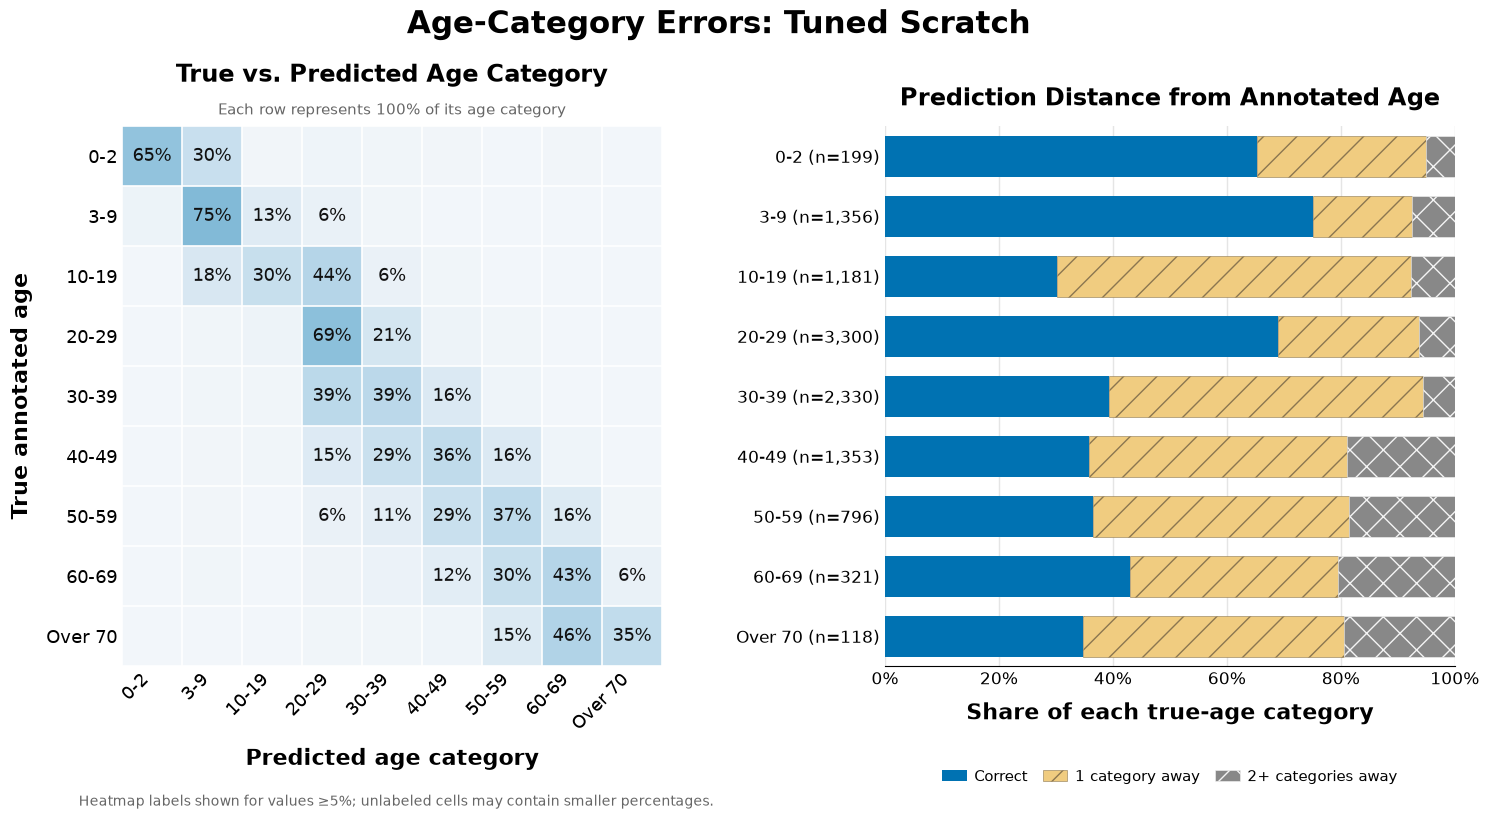

In [26]:
# Compact labels/legend and the 10-point note remain local for nine categories.
def plot_age_errors(run, title):

    # Saved FP32 final-test confusion matrix
    matrix = evidence["holdout"][run]["confusion"]

    if matrix.isna().any().any():
        raise ValueError("Incomplete confusion matrix.")

    counts = matrix.to_numpy()
    support = counts.sum(axis=1)

    if np.any(support == 0):
        raise ValueError("Each age category must have support.")

    shares = counts / support[:, None]

    # Category distance, not chronological years
    indices = np.arange(len(AGE_CLASSES))
    distance = np.abs(indices[:, None] - indices[None, :])

    correct = (shares * (distance == 0)).sum(axis=1)
    adjacent = (shares * (distance == 1)).sum(axis=1)
    distant = (shares * (distance >= 2)).sum(axis=1)

    # Shared Colors
    heat_colors = CONFUSION_CMAP
    correct_color = ERROR_COLORS["correct"]
    adjacent_color = ERROR_COLORS["one_away"]
    distant_color = ERROR_COLORS["two_or_more_away"]

    # Figure Layout
    fig, (ax_heat, ax_bars) = plt.subplots(
        1, 2,
        gridspec_kw={"width_ratios": [1.1, 1]},
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.96,
        top=0.83,
        bottom=0.23,
        wspace=0.30,
    )

    fig.suptitle(
        title,
        y=0.96,
    )

    # Confusion Heatmap

    ax_heat.imshow(
        shares,
        cmap=heat_colors,
        vmin=0,
        vmax=1,
        aspect="equal",
        interpolation="nearest",
    )

    ax_heat.set_title(
        "True vs. Predicted Age Category",
        pad=32,
    )

    # Short explanation of row normalization
    ax_heat.text(
        0.5, 1.015,
        "Each row represents 100% of its age category",
        transform=ax_heat.transAxes,
        ha="center",
        va="bottom",
        fontsize=11,
        color=NEUTRAL_COLORS["footer_text"],
        clip_on=False,
    )

    ax_heat.set_xticks(range(9))
    ax_heat.set_xticklabels(
        AGE_LABELS,
        rotation=45,
        ha="right",
    )

    ax_heat.set_yticks(range(9))
    ax_heat.set_yticklabels(AGE_LABELS)

    ax_heat.set_xlabel(
        "Predicted age category",
        labelpad=10,
    )

    ax_heat.set_ylabel(
        "True annotated age",
        labelpad=10,
    )

    ax_heat.tick_params(
        axis="both",
        labelsize=13,
        length=STYLE["hidden_tick_length"],
    )

    # Label percentages of at least 5%
    for row in range(9):
        for col in range(9):
            value = shares[row, col]

            if value >= 0.05:
                ax_heat.text(
                    col, row,
                    f"{value:.0%}",
                    ha="center",
                    va="center",
                    fontsize=13,
                    color=NEUTRAL_COLORS["text"],
                )

    # Cell Boundaries
    ax_heat.set_xticks(
        np.arange(-0.5, 9, 1),
        minor=True,
    )
    ax_heat.set_yticks(
        np.arange(-0.5, 9, 1),
        minor=True,
    )

    ax_heat.grid(
        which="minor",
        color=NEUTRAL_COLORS["white"],
        linewidth=STYLE["cell_border_width"],
    )

    ax_heat.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

    for spine in ax_heat.spines.values():
        spine.set_visible(False)

    # Prediction Distance

    y = np.arange(9)

    ax_bars.barh(
        y,
        correct,
        height=0.68,
        color=correct_color,
        label="Correct",
        zorder=3,
    )

    ax_bars.barh(
        y,
        adjacent,
        left=correct,
        height=0.68,
        color=adjacent_color,
        hatch="/",
        edgecolor=ERROR_COLORS["one_away_hatch"],
        linewidth=STYLE["hatch_border_width"],
        label="1 category away",
        zorder=3,
    )

    ax_bars.barh(
        y,
        distant,
        left=correct + adjacent,
        height=0.68,
        color=distant_color,
        hatch="x",
        edgecolor=ERROR_COLORS["two_or_more_hatch"],
        linewidth=STYLE["hatch_border_width"],
        label="2+ categories away",
        zorder=3,
    )

    ax_bars.set_title(
        "Prediction Distance from Annotated Age",
        pad=15,
    )

    ax_bars.set_yticks(y)
    ax_bars.set_yticklabels(
        [
            f"{age} (n={int(n):,})"
            for age, n in zip(AGE_LABELS, support)
        ]
    )

    ax_bars.set_ylim(8.5, -0.5)
    ax_bars.set_xlim(0, 1)

    ax_bars.set_xticks(np.arange(0, 1.01, 0.20))
    ax_bars.xaxis.set_major_formatter(
        PercentFormatter(1)
    )

    ax_bars.set_xlabel(
        "Share of each true-age category",
        labelpad=10,
    )

    ax_bars.tick_params(
        axis="both",
        labelsize=12.5,
        length=STYLE["hidden_tick_length"],
    )

    ax_bars.grid(visible=True, axis="x")
    ax_bars.set_axisbelow(True)

    ax_bars.spines["left"].set_visible(False)

    # Legend
    ax_bars.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        fontsize=11,
        columnspacing=1.0,
        handlelength=1.6,
        handletextpad=0.5,
        borderaxespad=0,
    )

    # Clarification about displayed percentages
    fig.text(
        0.10, 0.075,
        "Heatmap labels shown for values ≥5%; "
        "unlabeled cells may contain smaller percentages.",
        fontsize=10,
        color=NEUTRAL_COLORS["footer_text"],
    )

    return fig

# Tuned Scratch
fig = plot_age_errors(
    TUNED[0],
    "Age-Category Errors: Tuned Scratch",
)

plt.show()


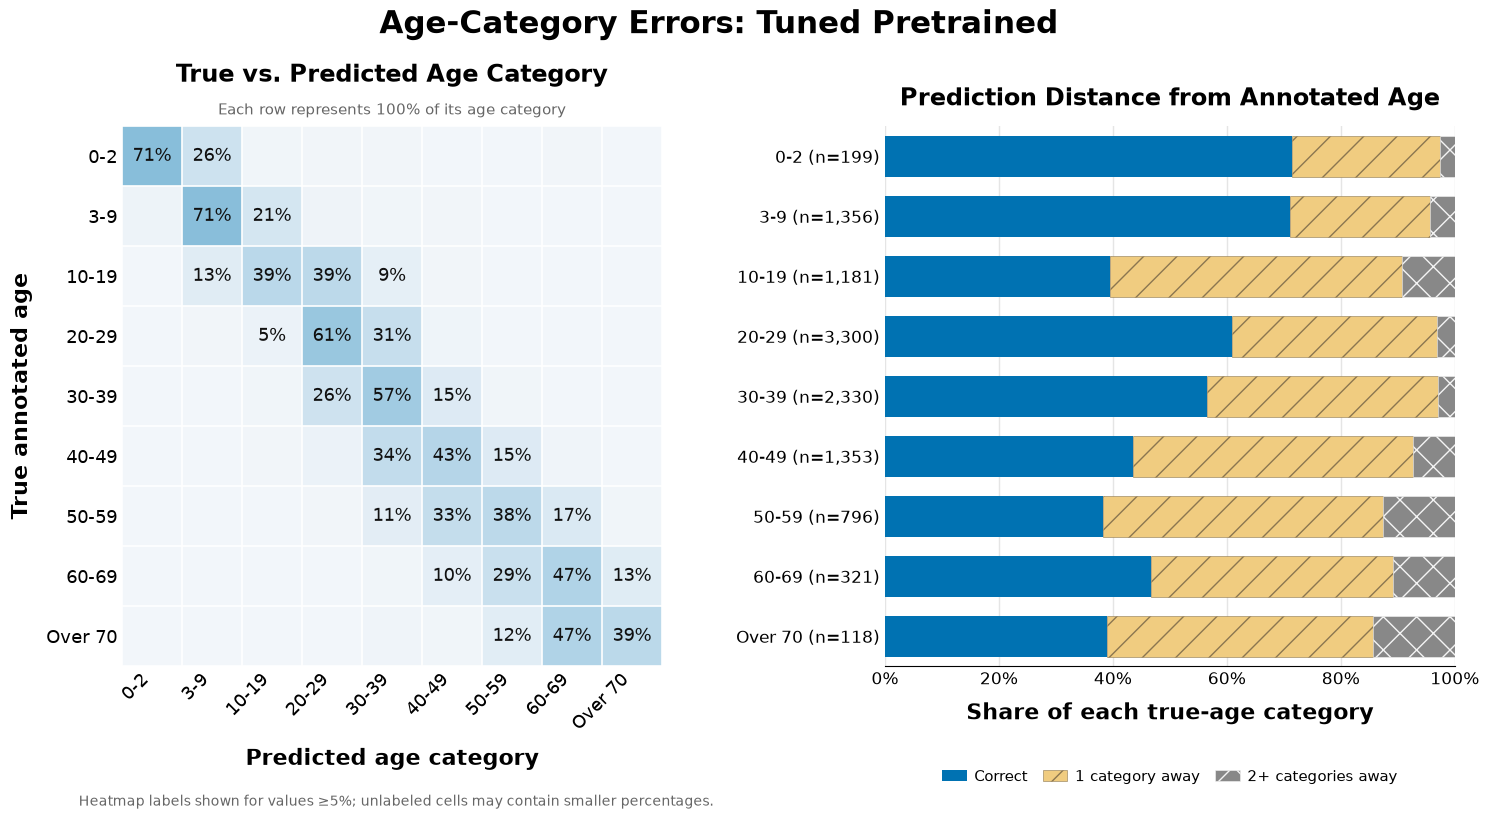

In [27]:
# Tuned Pretrained

fig = plot_age_errors(
    TUNED[1],
    "Age-Category Errors: Tuned Pretrained",
)

plt.show()


## Fig. 08. Accuracy differences by age and race

The plotted difference is tuned pretrained minus tuned scratch accuracy, in percentage points. Hatched cells have fewer than 30 images and show the count only. Estimates can still be noisy above that cutoff.


Holdout n=10,954; 52 differences shown; 11 low-support differences not shown. Positive = tuned pretrained higher; negative = tuned scratch higher.


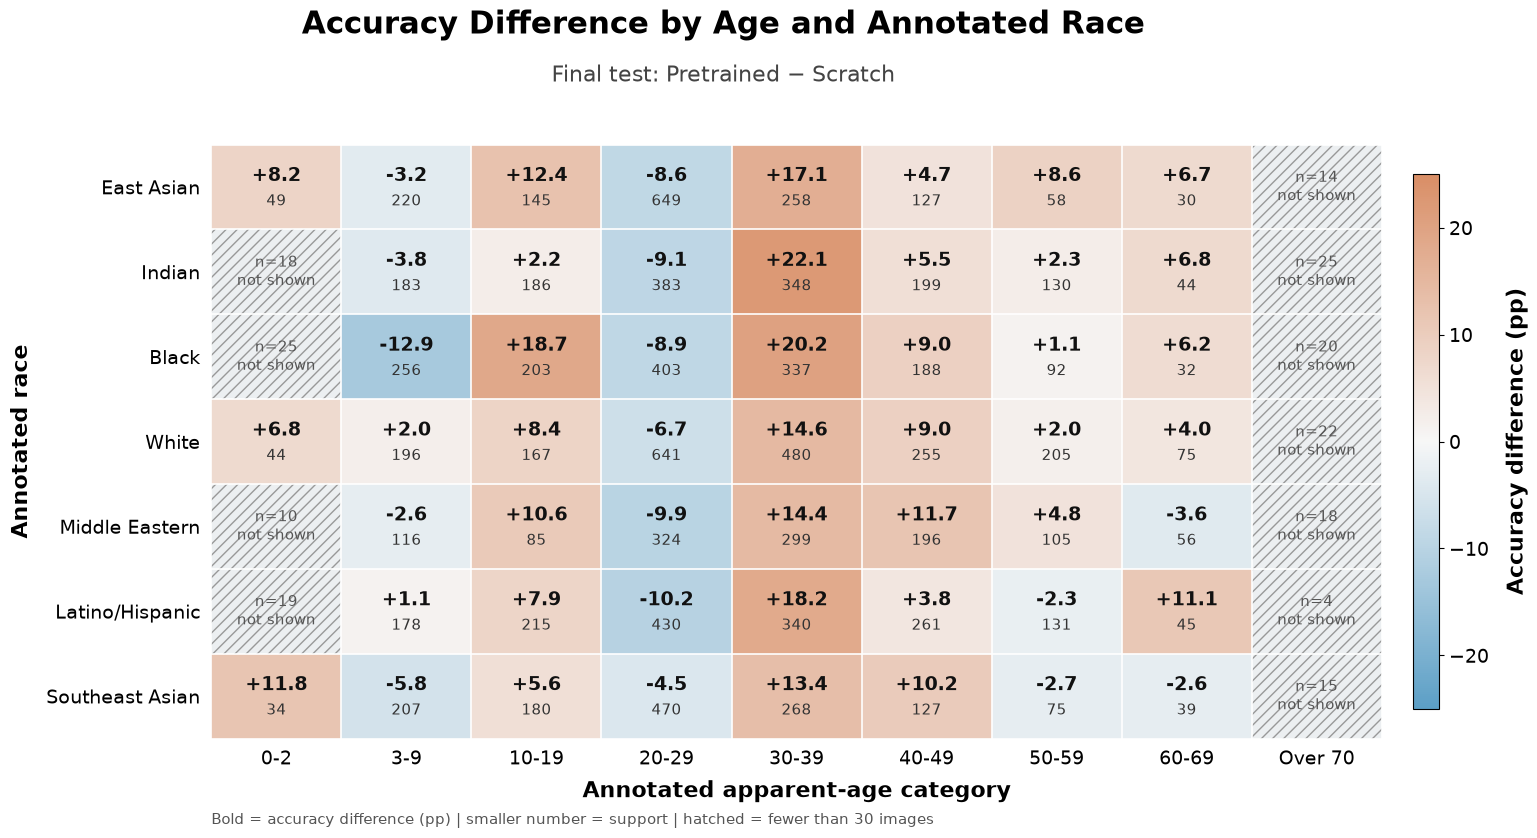

In [28]:
from matplotlib.colors import TwoSlopeNorm

scratch_run = "optuna-scratch-trial-0011"
pretrained_run = "optuna-pretrained-trial-0128"
subgroups = published["age_race"].query(
    "run in [@scratch_run, @pretrained_run] and checkpoint == 'best' "
    "and split == 'holdout' and evaluation_precision == 'fp32'"
)
if subgroups.groupby("run").size().to_dict() != {scratch_run: 63, pretrained_run: 63}:
    raise ValueError("Figure 08 requires 63 holdout groups for each tuned model.")

scratch_groups = subgroups.query("run == @scratch_run")
pretrained_groups = subgroups.query("run == @pretrained_run")
scratch_support = scratch_groups.pivot(index="race", columns="age", values="support").reindex(
    index=RACE_GROUPS, columns=AGE_CLASSES,
)
pretrained_support = pretrained_groups.pivot(index="race", columns="age", values="support").reindex(
    index=RACE_GROUPS, columns=AGE_CLASSES,
)
if (scratch_support.isna().any().any() or not scratch_support.equals(pretrained_support)
        or scratch_support.to_numpy().sum() != SPLITS["holdout"]):
    raise ValueError("Tuned models must have matching, complete holdout subgroup counts.")
scratch_accuracy = scratch_groups.pivot(index="race", columns="age", values="accuracy").reindex(
    index=RACE_GROUPS, columns=AGE_CLASSES,
)
pretrained_accuracy = pretrained_groups.pivot(index="race", columns="age", values="accuracy").reindex(
    index=RACE_GROUPS, columns=AGE_CLASSES,
)
support_08 = scratch_support.to_numpy()
visible_08 = support_08 >= 30
scratch_values = scratch_accuracy.to_numpy()
pretrained_values = pretrained_accuracy.to_numpy()
if (not np.isfinite(scratch_values[visible_08]).all()
        or not np.isfinite(pretrained_values[visible_08]).all()):
    raise ValueError("Shown groups require both published accuracies.")

# Suppressed accuracies are never required, filled or reconstructed.
difference_08_pp = np.full(support_08.shape, np.nan)
difference_08_pp[visible_08] = (
    pretrained_values[visible_08] - scratch_values[visible_08]
) * 100
masked_08 = np.ma.masked_where(~visible_08, difference_08_pp)
# Symmetric five-point bounds retain the approved −25 to +25 pp presentation.
limit_08 = max(5, float(np.ceil(np.abs(masked_08.compressed()).max() / 5) * 5))

fig, ax = plt.subplots()
fig.subplots_adjust(left=0.18, right=0.95, top=0.82, bottom=0.16)
fig.suptitle("Accuracy Difference by Age and Annotated Race", y=0.97)
fig.text(0.5, 0.89, "Final test: Pretrained − Scratch", ha="center",
         fontsize=16, color=NEUTRAL_COLORS["annotation_text"])
image = ax.imshow(
    masked_08, cmap=DIFFERENCE_CMAP,
    norm=TwoSlopeNorm(vmin=-limit_08, vcenter=0, vmax=limit_08),
    aspect="auto", interpolation="nearest",
)
for row in range(len(RACE_GROUPS)):
    for col in range(len(AGE_CLASSES)):
        n = int(support_08[row, col])
        if n < 30:
            ax.add_patch(Rectangle(
                (col - 0.5, row - 0.5), 1, 1, fill=False, hatch="///",
                edgecolor=NEUTRAL_COLORS["low_support_hatch"], linewidth=0,
            ))
            ax.text(col, row, f"n={n}\nnot shown", ha="center", va="center",
                    fontsize=11, color=NEUTRAL_COLORS["secondary_text"])
        else:
            ax.text(col, row - 0.13, f"{difference_08_pp[row, col]:+.1f}",
                    ha="center", va="center", fontsize=14, fontweight="bold",
                    color=NEUTRAL_COLORS["text"])
            ax.text(col, row + 0.17, f"{n:,}", ha="center", va="center",
                    fontsize=11, color=NEUTRAL_COLORS["dark"])

ax.set_xticks(range(len(AGE_CLASSES)), AGE_LABELS)
ax.set_yticks(range(len(RACE_GROUPS)), RACE_LABELS)
ax.set_xlabel("Annotated apparent-age category", fontweight="bold", labelpad=8)
ax.set_ylabel("Annotated race", fontweight="bold", labelpad=10)
ax.tick_params(axis="both", length=0, pad=8)
ax.set_xticks(np.arange(-0.5, len(AGE_CLASSES), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(RACE_GROUPS), 1), minor=True)
ax.grid(which="minor", color=NEUTRAL_COLORS["white"], linewidth=STYLE["cell_border_width"])
ax.tick_params(which="minor", bottom=False, left=False)
for spine in ax.spines.values():
    spine.set_visible(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.025, shrink=0.90)
colorbar.set_label("Accuracy difference (pp)", fontweight="bold")
colorbar.set_ticks(np.arange(-20, 21, 10))
fig.text(
    0.18, 0.065,
    "Bold = accuracy difference (pp) | smaller number = support | hatched = fewer than 30 images",
    fontsize=11, color=NEUTRAL_COLORS["secondary_text"],
)
print(f"Holdout n={support_08.sum():,}; {visible_08.sum()} differences shown; "
      f"{(~visible_08).sum()} low-support differences not shown. "
      "Positive = tuned pretrained higher; negative = tuned scratch higher.")
plt.show()
